<a href="https://colab.research.google.com/github/liverpoolisheart/2026linear-algebra-/blob/main/%ED%83%80%EC%9D%B4%ED%8C%8C%EC%9D%B4%ED%84%B0_%EA%B3%BC%EC%A0%9C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

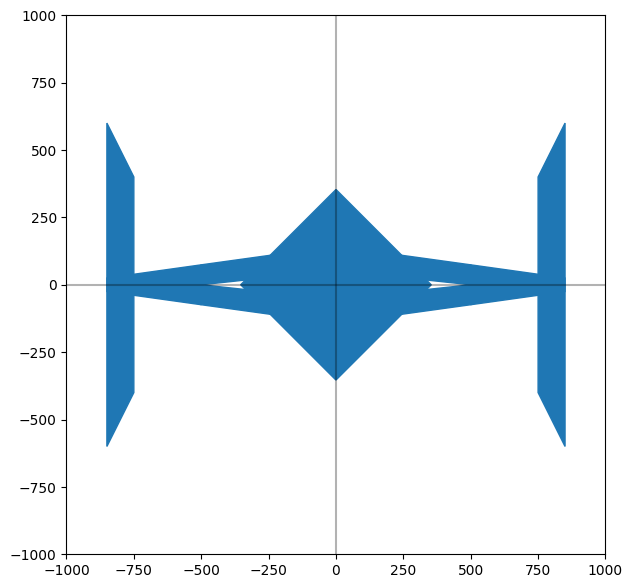

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

INF = 1000
LEN = 100


def translate(p, dx, dy):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[1.0, 0.0, dx],
                [0.0, 1.0, dy],
                [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  q = np.array([q[0], q[1]])
  return q


def rotate(p, theta):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[np.cos(theta), -np.sin(theta), 0.0],
                [np.sin(theta),  np.cos(theta), 0.0],
                [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  q = np.array([q[0], q[1]])
  return q


def scale(p, sx, sy):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[sx, 0.0, 0.0],
                [0.0, sy, 0.0],
                [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  q = np.array([q[0], q[1]])
  return q


def shear_x(p, h):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[1.0, h,   0.0],
                [0.0, 1.0, 0.0],
                [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  q = np.array([q[0], q[1]])
  return q


def shear_y(p, h):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[1.0, 0.0, 0.0],
                [h,   1.0, 0.0],
                [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  q = np.array([q[0], q[1]])
  return q


def reflect_x(p):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[1.0,  0.0, 0.0],
                [0.0, -1.0, 0.0],
                [0.0,  0.0, 1.0]])
  q = np.dot(m, hp)
  q = np.array([q[0], q[1]])
  return q


def reflect_y(p):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[-1.0, 0.0, 0.0],
                [ 0.0, 1.0, 0.0],
                [ 0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  q = np.array([q[0], q[1]])
  return q


def reflect_origin(p):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[-1.0,  0.0, 0.0],
                [ 0.0, -1.0, 0.0],
                [ 0.0,  0.0, 1.0]])
  q = np.dot(m, hp)
  q = np.array([q[0], q[1]])
  return q


def reflect_yx(p):
  hp = np.array([p[0], p[1], 1.0])
  m = np.array([[0.0, 1.0, 0.0],
                [1.0, 0.0, 0.0],
                [0.0, 0.0, 1.0]])
  q = np.dot(m, hp)
  q = np.array([q[0], q[1]])
  return q


def draw_axis(ax):
  ax.axhline(0, color='black', alpha=0.3)
  ax.axvline(0, color='black', alpha=0.3)
  ax.set_xlim(-INF, INF)
  ax.set_ylim(-INF, INF)
  ax.set_aspect('equal')


def draw_rectangle(ax, p1, p2, p3, p4):
  my_polygon = Polygon([p1, p2, p3, p4], color='C0')
  ax.add_patch(my_polygon)


def draw_cockpit(ax, p1, p2, p3, p4):
  q1 = translate(p1, -LEN/2, -LEN/2)
  q2 = translate(p2, -LEN/2, -LEN/2)
  q3 = translate(p3, -LEN/2, -LEN/2)
  q4 = translate(p4, -LEN/2, -LEN/2)

  s = 5
  q1 = scale(q1, s, s)
  q2 = scale(q2, s, s)
  q3 = scale(q3, s, s)
  q4 = scale(q4, s, s)

  q1 = rotate(q1, 3.14/4.0)
  q2 = rotate(q2, 3.14/4.0)
  q3 = rotate(q3, 3.14/4.0)
  q4 = rotate(q4, 3.14/4.0)

  draw_rectangle(ax, q1, q2, q3, q4)


def draw_left_arm(ax, p1, p2, p3, p4):
  q1 = scale(p1, 2.6, 0.82)
  q2 = scale(p2, 2.6, 0.74)
  q3 = scale(p3, 2.6, 0.74)
  q4 = scale(p4, 2.6, 0.82)

  q1 = translate(q1, 240, 28)
  q2 = translate(q2, 240, 0)
  q3 = translate(q3, 240, 0)
  q4 = translate(q4, 240, 28)

  r1 = scale(p1, 3.5, 1.48)
  r2 = scale(p2, 3.5, 0.5)
  r3 = scale(p3, 3.5, 0.5)
  r4 = scale(p4, 3.5, 1.48)

  r1 = translate(r1, 500, -74)
  r2 = translate(r2, 500, -25)
  r3 = translate(r3, 500, -25)
  r4 = translate(r4, 500, -74)

  draw_rectangle(ax, q1, q2, q3, q4)
  draw_rectangle(ax, reflect_x(q1), reflect_x(q2), reflect_x(q3), reflect_x(q4))
  draw_rectangle(ax, r1, r2, r3, r4)


def draw_left_wing(ax, p1, p2, p3, p4):
  q1 = scale(p1, 1, 12)
  q2 = scale(p2, 1, 8)
  q3 = scale(p3, 1, 8)
  q4 = scale(p4, 1, 12)

  q1 = translate(q1, -850, -600)
  q2 = translate(q2, -850, -400)
  q3 = translate(q3, -850, -400)
  q4 = translate(q4, -850, -600)

  q1 = reflect_y(q1)
  q2 = reflect_y(q2)
  q3 = reflect_y(q3)
  q4 = reflect_y(q4)

  draw_rectangle(ax, q1, q2, q3, q4)


def draw_right_arm(ax, p1, p2, p3, p4):
  q1 = scale(p1, 2.6, 0.82)
  q2 = scale(p2, 2.6, 0.74)
  q3 = scale(p3, 2.6, 0.74)
  q4 = scale(p4, 2.6, 0.82)

  q1 = translate(q1, 240, 28)
  q2 = translate(q2, 240, 0)
  q3 = translate(q3, 240, 0)
  q4 = translate(q4, 240, 28)

  r1 = scale(p1, 3.5, 1.48)
  r2 = scale(p2, 3.5, 0.5)
  r3 = scale(p3, 3.5, 0.5)
  r4 = scale(p4, 3.5, 1.48)

  r1 = translate(r1, 500, -74)
  r2 = translate(r2, 500, -25)
  r3 = translate(r3, 500, -25)
  r4 = translate(r4, 500, -74)

  draw_rectangle(ax, reflect_y(q1), reflect_y(q2), reflect_y(q3), reflect_y(q4))
  draw_rectangle(ax, reflect_origin(q1), reflect_origin(q2), reflect_origin(q3), reflect_origin(q4))
  draw_rectangle(ax, reflect_y(r1), reflect_y(r2), reflect_y(r3), reflect_y(r4))


def draw_right_wing(ax, p1, p2, p3, p4):
  q1 = scale(p1, 1, 12)
  q2 = scale(p2, 1, 8)
  q3 = scale(p3, 1, 8)
  q4 = scale(p4, 1, 12)

  q1 = translate(q1, -850, -600)
  q2 = translate(q2, -850, -400)
  q3 = translate(q3, -850, -400)
  q4 = translate(q4, -850, -600)

  draw_rectangle(ax, q1, q2, q3, q4)


def draw_object(ax):
  p1 = np.array([0, 0])
  p2 = np.array([LEN, 0])
  p3 = np.array([LEN, LEN])
  p4 = np.array([0, LEN])

  draw_cockpit(ax, p1, p2, p3, p4)
  draw_left_arm(ax, p1, p2, p3, p4)
  draw_left_wing(ax, p1, p2, p3, p4)
  draw_right_arm(ax, p1, p2, p3, p4)
  draw_right_wing(ax, p1, p2, p3, p4)


fig, ax = plt.subplots(figsize=(7, 7))

draw_axis(ax)

draw_object(ax)

plt.show()